In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [2]:
path = 'datasets/Mall_Customers.csv'
data = pd.read_csv(path)

In [3]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
x = data[['Age' , 'Annual Income (k$)' ,'Spending Score (1-100)']]
x.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
x_scaled[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

In [6]:
model = DBSCAN(
    min_samples = 3,
    eps = 0.6
)

In [7]:
labels = model.fit_predict(x_scaled)
labels

array([-1,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0, -1,  0,  0, -1,  0,  0,
        0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0, -1,  1,  0,  1,  0,  1, -1,  1,  0,  1,  0,  1,  2,  1,
        0,  1,  2,  1, -1,  1,  0,  1,  2,  1,  0,  1,  0,  1,  0,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  1,  2,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1, -1,
        1,  0,  1,  0,  1, -1,  1, -1,  1, -1,  1, -1,  1])

In [8]:
data['clusters'] = labels

In [9]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),clusters
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,0
2,3,Female,20,16,6,-1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [10]:
data['clusters'].value_counts()

clusters
 0    143
 1     39
-1     14
 2      4
Name: count, dtype: int64

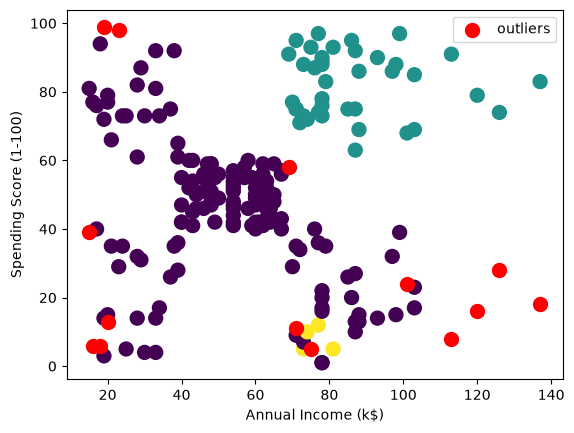

In [11]:
sns.scatterplot(data = data , x = 'Annual Income (k$)' , y='Spending Score (1-100)',
               # hue = 'cluster' ,
               # palette='tab10',
               s=100,
               # label = 'datapoint'
               )

clustered = data[data['clusters']!=-1]
plt.scatter(
    clustered['Annual Income (k$)'],
    clustered['Spending Score (1-100)']
    , c=clustered['clusters'],
    cmap='viridis',
    s=100,
    # label='clusters'
)
noise=data[data['clusters']==-1]
plt.scatter(
    noise['Annual Income (k$)'],
    noise['Spending Score (1-100)'],
    color='red',
    s=100,
    label='outliers'
)

plt.legend()